# Guide pour l'Appel à une API Hugging Face pour la Segmentation d'Images

Bienvenue ! Ce notebook a pour but de vous guider pas à pas dans l'utilisation de l'API d'inférence de Hugging Face pour effectuer de la segmentation d'images. La segmentation d'images consiste à attribuer une étiquette (comme "cheveux", "vêtement", "arrière-plan") à chaque pixel d'une image.

Nous allons :
1. Comprendre ce qu'est une API et comment s'y connecter.
2. Envoyer une image à un modèle de segmentation hébergé sur Hugging Face.
3. Récupérer et interpréter les résultats.
4. Visualiser les masques de segmentation.
5. Étendre cela pour traiter plusieurs images.

## 1. Configuration Initiale et Importations

Commençons par importer les bibliothèques Python nécessaires. Nous aurons besoin de :
- `os` pour interagir avec le système de fichiers (lister les images).
- `requests` pour effectuer des requêtes HTTP vers l'API.
- `PIL (Pillow)` pour manipuler les images.
- `matplotlib.pyplot` pour afficher les images et les masques.
- `numpy` pour la manipulation des tableaux (les images sont des tableaux de pixels).
- `tqdm.notebook` pour afficher une barre de progression (utile pour plusieurs images).
- `base64` et `io` pour décoder les masques renvoyés par l'API.

In [1]:
import os
import requests
from PIL import Image
import matplotlib.pyplot as plt
import numpy as np
from tqdm.auto import tqdm
import base64
import io
# Je rajoute cet import pour avoir ma clé API en dehors du script dans un .env et donc pouvoir l'appeler
from dotenv import load_dotenv
# Je rajoute glob car c'est ce que j'ai trouvé de plus simple pour lister les fichiers
import glob
# Je mets time pour pouvoir mettre un peu de délai entre les appels à l'API
import time
# pandas je l'utilise en toute fin pour faire l'évaluation de perf du modèle
import pandas as pd


In [2]:
print(os.getcwd())

d:\GitProjets\Projet2


### Variables de Configuration

Nous devons définir quelques variables :
- `image_dir`: Le chemin vers le dossier contenant vos images. **Assurez-vous de modifier ce chemin si nécessaire.**
- `max_images`: Le nombre maximum d'images à traiter (pour ne pas surcharger l'API ou attendre trop longtemps).
- `api_token`: Votre jeton d'API Hugging Face. **IMPORTANT : Gardez ce jeton secret !**

**Comment obtenir un token API Hugging Face ?**
1. Créez un compte sur [huggingface.co](https://huggingface.co/).
2. Allez dans votre profil -> Settings -> Access Tokens.
3. Créez un nouveau token (par exemple, avec le rôle "read").
4. Copiez ce token ici.

In [3]:
# TODO: Modifiez ces valeurs selon votre configuration
image_dir = "/data/IMG"  # Exemple : si vous êtes sur Colab et avez uploadé un dossier
max_images = 3  # Commençons avec peu d'images

# IMPORTANT: Remplacez "VOTRE_TOKEN_HUGGING_FACE_ICI" par votre véritable token API.
# Ne partagez jamais votre token publiquement.
#api_token = ""
# Je m'entraîne à bien travailler avec les fichiers .env, donc j'ai fait avec
load_dotenv("/.env")
api_token = os.getenv("API_KEY_HUGGIN")

# Créons le dossier d'images s'il n'existe pas (pour l'exemple)
if not os.path.exists(image_dir):
    os.makedirs(image_dir)
    print(f"Dossier '{image_dir}' créé. Veuillez y ajouter des images .jpg ou .png.")
else:
    print(f"Dossier '{image_dir}' existant.")

if api_token == "VOTRE_TOKEN_HUGGING_FACE_ICI":
    print("\nATTENTION : Vous devez remplacer 'VOTRE_TOKEN_HUGGING_FACE_ICI' par votre token API personnel.")


Dossier '/data/IMG' existant.


## 2. Comprendre l'API d'Inférence Hugging Face

L'API d'inférence permet d'utiliser des modèles hébergés sur Hugging Face sans avoir à les télécharger ou à gérer l'infrastructure.

- **Modèle utilisé** : Nous allons utiliser le modèle `sayeed99/segformer_b3_clothes`, spécialisé dans la segmentation de vêtements et de parties du corps.
- **URL de l'API** : L'URL pour un modèle est généralement `https://api-inference.huggingface.co/models/NOM_DU_MODELE`.
- **Headers (En-têtes)** : Pour s'authentifier et spécifier le type de contenu, nous envoyons des en-têtes avec notre requête.
    - `Authorization`: Contient notre token API (précédé de `Bearer `).
    - `Content-Type`: Indique que nous envoyons une image au format JPEG (ou PNG selon le cas).

In [4]:
#API_URL = "https://api-inference.huggingface.co/models/sayeed99/segformer_b3_clothes" # Remplacez ... par le bon endpoint.
# Le premier lien semblait cassé, à priori ça a changé d'adresse
API_URL = "https://router.huggingface.co/hf-inference/models/sayeed99/segformer_b3_clothes" # Remplacez ... par le bon endpoint.
headers = {
    "Authorization": f"Bearer {api_token}"
    # Le "Content-Type" sera ajouté dynamiquement lors de l'envoi de l'image
}

# Lister les chemins des images à traiter
# Assurez-vous d'avoir des images dans le dossier 'image_dir'!
# A vous de jouer !

image_paths = glob.glob('data/IMG/*.png')

if not image_paths:
    print(f"Aucune image trouvée dans '{image_dir}'. Veuillez y ajouter des images.")
else:
    print(f"{len(image_paths)} image(s) à traiter : {image_paths}")

50 image(s) à traiter : ['data/IMG\\image_0.png', 'data/IMG\\image_1.png', 'data/IMG\\image_10.png', 'data/IMG\\image_11.png', 'data/IMG\\image_12.png', 'data/IMG\\image_13.png', 'data/IMG\\image_14.png', 'data/IMG\\image_15.png', 'data/IMG\\image_16.png', 'data/IMG\\image_17.png', 'data/IMG\\image_18.png', 'data/IMG\\image_19.png', 'data/IMG\\image_2.png', 'data/IMG\\image_20.png', 'data/IMG\\image_21.png', 'data/IMG\\image_22.png', 'data/IMG\\image_23.png', 'data/IMG\\image_24.png', 'data/IMG\\image_25.png', 'data/IMG\\image_26.png', 'data/IMG\\image_27.png', 'data/IMG\\image_28.png', 'data/IMG\\image_29.png', 'data/IMG\\image_3.png', 'data/IMG\\image_30.png', 'data/IMG\\image_31.png', 'data/IMG\\image_32.png', 'data/IMG\\image_33.png', 'data/IMG\\image_34.png', 'data/IMG\\image_35.png', 'data/IMG\\image_36.png', 'data/IMG\\image_37.png', 'data/IMG\\image_38.png', 'data/IMG\\image_39.png', 'data/IMG\\image_4.png', 'data/IMG\\image_40.png', 'data/IMG\\image_41.png', 'data/IMG\\image_4

## 3. Fonctions Utilitaires pour le Traitement des Masques

Le modèle que nous utilisons (`sayeed99/segformer_b3_clothes`) renvoie des masques pour différentes classes (cheveux, chapeau, etc.). Ces masques sont encodés en base64. Les fonctions ci-dessous sont fournies pour vous aider à :
1.  `CLASS_MAPPING`: Un dictionnaire qui associe les noms de classes (ex: "Hat") à des identifiants numériques.
2.  `get_image_dimensions`: Récupérer les dimensions d'une image.
3.  `decode_base64_mask`: Décoder un masque de base64 en une image (tableau NumPy) et le redimensionner.
4.  `create_masks`: Combiner les masques de toutes les classes détectées en un seul masque de segmentation final, où chaque pixel a la valeur de l'ID de sa classe.

**Cette partie est donnée car elle est spécifique au format de sortie de ce modèle et un peu complexe pour une première approche.** Lisez-la pour comprendre son rôle, mais ne vous attardez pas sur les détails d'implémentation pour l'instant.

In [5]:
CLASS_MAPPING = {
    "Background": 0,
    "Hat": 1,
    "Hair": 2,
    "Sunglasses": 3,
    "Upper-clothes": 4,
    "Skirt": 5,
    "Pants": 6,
    "Dress": 7,
    "Belt": 8,
    "Left-shoe": 9,
    "Right-shoe": 10,
    "Face": 11,
    "Left-leg": 12,
    "Right-leg": 13,
    "Left-arm": 14,
    "Right-arm": 15,
    "Bag": 16,
    "Scarf": 17
}

def get_image_dimensions(img_path):
    """
    Get the dimensions of an image.

    Args:
        img_path (str): Path to the image.

    Returns:
        tuple: (width, height) of the image.
    """
    original_image = Image.open(img_path)
    return original_image.size

def decode_base64_mask(base64_string, width, height):
    """
    Decode a base64-encoded mask into a NumPy array.

    Args:
        base64_string (str): Base64-encoded mask.
        width (int): Target width.
        height (int): Target height.

    Returns:
        np.ndarray: Single-channel mask array.
    """
    mask_data = base64.b64decode(base64_string)
    mask_image = Image.open(io.BytesIO(mask_data))
    mask_array = np.array(mask_image)
    if len(mask_array.shape) == 3:
        mask_array = mask_array[:, :, 0]  # Take first channel if RGB
    mask_image = Image.fromarray(mask_array).resize((width, height), Image.NEAREST)
    return np.array(mask_image)

def create_masks(results, width, height):
    """
    Combine multiple class masks into a single segmentation mask.

    Args:
        results (list): List of dictionaries with 'label' and 'mask' keys.
        width (int): Target width.
        height (int): Target height.

    Returns:
        np.ndarray: Combined segmentation mask with class indices.
    """
    combined_mask = np.zeros((height, width), dtype=np.uint8)  # Initialize with Background (0)

    # Process non-Background masks first
    for result in results:
        label = result['label']
        class_id = CLASS_MAPPING.get(label, 0)
        if class_id == 0:  # Skip Background
            continue
        mask_array = decode_base64_mask(result['mask'], width, height)
        combined_mask[mask_array > 0] = class_id

    # Process Background last to ensure it doesn't overwrite other classes unnecessarily
    # (Though the model usually provides non-overlapping masks for distinct classes other than background)
    for result in results:
        if result['label'] == 'Background':
            mask_array = decode_base64_mask(result['mask'], width, height)
            # Apply background only where no other class has been assigned yet
            # This logic might need adjustment based on how the model defines 'Background'
            # For this model, it seems safer to just let non-background overwrite it first.
            # A simple application like this should be fine: if Background mask says pixel is BG, set it to 0.
            # However, a more robust way might be to only set to background if combined_mask is still 0 (initial value)
            combined_mask[mask_array > 0] = 0 # Class ID for Background is 0

    return combined_mask

## 4. Segmentation d'une Seule Image

Avant de traiter toutes les images, concentrons-nous sur une seule pour bien comprendre le processus.

Étapes :
1.  Choisir une image.
2.  Ouvrir l'image en mode binaire (`"rb"`) et lire son contenu (`data`).
3.  Déterminer le `Content-Type` (par exemple, `"image/jpeg"` ou `"image/png"`).
4.  Envoyer la requête POST à l'API avec `requests.post()` en passant l'URL, les headers et les données.
5.  Vérifier le code de statut de la réponse. Une erreur sera levée si le code n'est pas 2xx (succès) grâce à `response.raise_for_status()`.
6.  Convertir la réponse JSON en un dictionnaire Python avec `response.json()`.
7.  Utiliser nos fonctions `get_image_dimensions` et `create_masks` pour obtenir le masque final.
8.  Afficher l'image originale et le masque segmenté.

In [6]:
import matplotlib.patches as mpatches
import matplotlib.colors as mcolors

# À définir une fois, avant la boucle sur les images (réutilisable pour l'étape 5)
id_to_class = {v: k for k, v in CLASS_MAPPING.items()}
n_classes = len(CLASS_MAPPING)
cmap = plt.get_cmap("tab20", n_classes)
norm = mcolors.Normalize(vmin=0, vmax=n_classes - 1)

Traitement de l'image : data/IMG\image_0.png


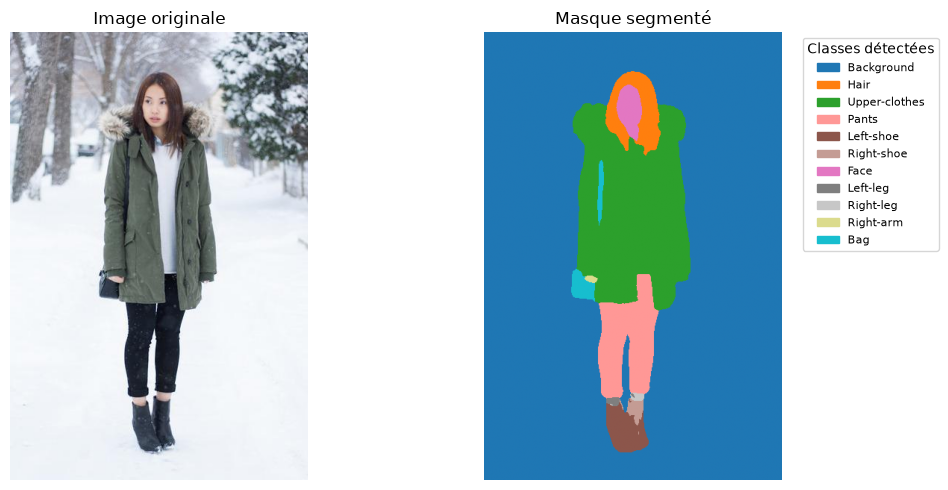

In [7]:
if image_paths:
    single_image_path = image_paths[0] # Prenons la première image de notre liste
    print(f"Traitement de l'image : {single_image_path}")

    try:
        # Lire l'image en binaire
        # Et mettez le contenu de l'image dans la variable image_data
        with open(single_image_path, "rb") as f:
            image_data = f.read()

        # Maintenant, utilisez l'API huggingface
        # ainsi que les fonctions données plus haut pour ségmenter vos images.
        # Déterminer le Content-Type
        content_type = "image/png" if single_image_path.lower().endswith(".png") else "image/jpeg"
        headers["Content-Type"] = content_type

        # Envoyer la requête POST
        response = requests.post(API_URL, headers=headers, data=image_data)

        # Vérifier le statut (lève une exception si erreur)
        response.raise_for_status()

        # Convertir la réponse JSON
        results = response.json()

        # Récupérer les dimensions et construire le masque final
        width, height = get_image_dimensions(single_image_path)
        final_mask = create_masks(results, width, height)

        # Afficher l'image originale et le masque
        fig, axes = plt.subplots(1, 2, figsize=(12, 5))
        axes[0].imshow(Image.open(single_image_path))
        axes[0].set_title("Image originale")
        axes[0].axis("off")
        axes[1].imshow(final_mask, cmap=cmap, norm=norm)
        axes[1].set_title("Masque segmenté")
        axes[1].axis("off")

        # Légende : uniquement les classes réellement présentes dans CE masque
        present_ids = np.unique(final_mask)
        legend_patches = [
            mpatches.Patch(color=cmap(norm(cls_id)), label=id_to_class.get(cls_id, f"Classe {cls_id}"))
            for cls_id in present_ids
        ]
        axes[1].legend(
            handles=legend_patches,
            bbox_to_anchor=(1.05, 1),
            loc="upper left",
            fontsize=8,
            title="Classes détectées"
        )

        plt.tight_layout()
        plt.show()

    except Exception as e:
        print(f"Une erreur est survenue : {e}")
else:
    print("Aucune image à traiter. Vérifiez la configuration de 'image_dir' et 'max_images'.")

## 5. Segmentation de Plusieurs Images (Batch)

Maintenant que nous savons comment traiter une image, nous pouvons créer une fonction pour en traiter plusieurs.
Cette fonction va boucler sur la liste `image_paths` et appliquer la logique de segmentation à chaque image.
Nous utiliserons `tqdm` pour avoir une barre de progression.

In [8]:
#Je fais une fonction de ce qu'on a fait plus haut afin de pouvoir l'appeler plus fcilement par la suite
def segment_single_image(image_path):
    """Segmente une seule image"""
    with open(image_path, "rb") as f:
        image_data = f.read()

    content_type = "image/png" if image_path.lower().endswith(".png") else "image/jpeg"
    headers["Content-Type"] = content_type

    response = requests.post(API_URL, headers=headers, data=image_data)
    response.raise_for_status()
    results = response.json()

    width, height = get_image_dimensions(image_path)
    return create_masks(results, width, height)

def segment_images_batch(list_of_image_paths):
    """
    Segmente une liste d'images en utilisant l'API Hugging Face.

    Args:
        list_of_image_paths (list): Liste des chemins vers les images.

    Returns:
        list: Liste des masques de segmentation (tableaux NumPy).
              Contient None si une image n'a pas pu être traitée.
    """
    batch_segmentations = []

    for image_path in tqdm(list_of_image_paths, desc="Segmentation en cours"):
        try:
            mask = segment_single_image(image_path)
            batch_segmentations.append(mask)
        except Exception as e:
            print(f"Erreur sur {image_path} : {e}")
            batch_segmentations.append(None)

        # N'oubliez pas de mettre une pause entre chaque appel API !
        time.sleep(2)

    return batch_segmentations

# Appeler la fonction pour segmenter les images listées dans image_paths
if image_paths:
    print(f"\nTraitement de {len(image_paths)} image(s) en batch...")
    batch_seg_results = segment_images_batch(image_paths)
    print("Traitement en batch terminé.")
else:
    batch_seg_results = []
    print("Aucune image à traiter en batch.")


Traitement de 50 image(s) en batch...


Segmentation en cours:   0%|          | 0/50 [00:00<?, ?it/s]

Traitement en batch terminé.


## 6. Affichage des Résultats en Batch

Nous allons maintenant créer une fonction pour afficher les images originales et leurs segmentations correspondantes côte à côte, dans une grille.




In [9]:
def display_segmented_images_batch(original_image_paths, segmentation_masks):
    """
    Affiche les images originales et leurs masques segmentés.

    Args:
        original_image_paths (list): Liste des chemins des images originales.
        segmentation_masks (list): Liste des masques segmentés (NumPy arrays).
    """
    # Matplotlib, ça vous parle ?
    # Alors... au travail ! 😉

    n = len(original_image_paths)
    # J'avais un plantage si je ne faisait pas grandir le layout, donc j'intègre le figsize=(10, 5 * n)
    fig, axes = plt.subplots(n, 2, figsize=(10, 5 * n))

    # Cette ligne m'a été suggérée par une IA, mais je suppose que nous ne rencontrerons pas le cas dans cet exercice
    # Il s'agit de ne pas avoir de plantage si il n'y a qu'une seule image et donc de forcer la forme
    if n == 1:
        axes = axes.reshape(1, 2)
    # Grace à enumerate je peux faire un couple image originale / masque pour ensuite pouvoir les positionner côte à côte dans l'affichage
    for i, (path, mask) in enumerate(zip(original_image_paths, segmentation_masks)):
        axes[i, 0].imshow(Image.open(path))
        axes[i, 0].set_title(f"Originale : {os.path.basename(path)}")
        axes[i, 0].axis("off")
    # Pour ne pas casser l'affichage si une image n'a pas pu être traitée dans le segmentation batch
    # J'affiche donc une cellule échec si le mask est à none
        if mask is None:
            axes[i, 1].text(0.5, 0.5, "Échec de la segmentation",
                             ha="center", va="center", fontsize=10, color="red")
            axes[i, 1].axis("off")
            continue
    # Sinon on affiche bien le résultat
        axes[i, 1].imshow(mask, cmap=cmap, norm=norm)
        axes[i, 1].set_title("Masque segmenté")
        axes[i, 1].axis("off")
    # Et la légence uniquement pour les catégories de vêtements qui ont été trouvées
        present_ids = np.unique(mask)
        legend_patches = [
            mpatches.Patch(color=cmap(norm(cls_id)), label=id_to_class.get(cls_id, f"Classe {cls_id}"))
            for cls_id in present_ids
        ]
        axes[i, 1].legend(
            handles=legend_patches,
            bbox_to_anchor=(1.05, 1),
            loc="upper left",
            fontsize=7,
            title="Classes détectées"
        )

    plt.tight_layout()
    plt.show()

# Afficher les résultats du batch
if batch_seg_results:
    display_segmented_images_batch(image_paths, batch_seg_results)
else:
    print("Aucun résultat de segmentation à afficher.")

In [11]:
# On va évaluer ici les performances du modèle par rapport aux pasques Ground Truth qui ont été fournis dans l'exercice
# C'est avec Claude que j'ai trouvé la méthode avec sorted(glob.glob) cela me paraît mieux si jamais les fichiers n'étaient pas nommés correctement
# Mais est-ce que ça ne serait pas trop lourd sur un grand jeu d'images ?

img_paths = sorted(glob.glob('data/IMG/*.png'))
gt_mask_paths = sorted(glob.glob('data/Mask/*.png'))

print(f"{len(img_paths)} images, {len(gt_mask_paths)} masques GT")
for img_p, mask_p in zip(img_paths[:5], gt_mask_paths[:5]):
    print(os.path.basename(img_p), "<->", os.path.basename(mask_p))

50 images, 50 masques GT
image_0.png <-> mask_0.png
image_1.png <-> mask_1.png
image_10.png <-> mask_10.png
image_11.png <-> mask_11.png
image_12.png <-> mask_12.png


In [12]:
# Une fois que je suis sûr qu'il va comparer le bon masque avec la bonne image
# On fait une première fonction pour calculer le taux de correspondance par Classe entre deux Masques
def compute_iou_per_class(pred_mask, gt_mask, class_ids):
    ious = {}
    for cls_id, cls_name in class_ids.items():
        pred_cls = (pred_mask == cls_id)
        gt_cls = (gt_mask == cls_id)
        intersection = np.logical_and(pred_cls, gt_cls).sum()
        union = np.logical_or(pred_cls, gt_cls).sum()
        if union == 0:
            continue  # classe absente des deux masques, on l'ignore
        ious[cls_name] = intersection / union
    return ious
# Une autre fonction pour stocker les résultats iou d'une façon exploitable
def evaluate_model(img_paths, gt_mask_paths, class_mapping):
    id_to_class_local = {v: k for k, v in class_mapping.items()}
    rows = []

    for img_path, gt_path in tqdm(list(zip(img_paths, gt_mask_paths)), desc="Évaluation"):
        try:
            pred_mask = segment_single_image(img_path)
        except Exception as e:
            print(f"Erreur API sur {os.path.basename(img_path)} : {e}")
            continue

        gt_mask = np.array(Image.open(gt_path))
        if gt_mask.ndim == 3:
            gt_mask = gt_mask[:, :, 0]

        # Suggestion Claude : Sécurité : recaler les tailles si jamais elles diffèrent
        if gt_mask.shape != pred_mask.shape:
            gt_mask = np.array(
                Image.fromarray(gt_mask).resize(
                    (pred_mask.shape[1], pred_mask.shape[0]), Image.NEAREST
                )
            )

        ious = compute_iou_per_class(pred_mask, gt_mask, id_to_class_local)
        ious["image"] = os.path.basename(img_path)
        rows.append(ious)

        time.sleep(2)  # on respecte le rate limit de l'API, comme pour le batch

    return pd.DataFrame(rows).set_index("image")

In [ ]:
# Affichage brut des résultats pour validation à l'oeil
results_df = evaluate_model(img_paths, gt_mask_paths, CLASS_MAPPING)
results_df

Évaluation:   0%|          | 0/50 [00:00<?, ?it/s]

,Background,Hair,Upper-clothes,Pants,Left-shoe,Right-shoe,Face,Left-leg,Right-leg,Right-arm,Bag,Hat,Skirt,Belt,Left-arm,Sunglasses,Dress,Scarf
image,,,,,,,,,,,,,,,,,,
image_0.png,0.986553,0.759374,0.924587,0.896533,0.289666,0.007881,0.829651,0.039813,0.007538,0.873239,0.521262,NaN,NaN,NaN,NaN,NaN,NaN,NaN
image_1.png,0.970064,0.871255,0.858584,0.848530,0.171558,0.166296,0.737162,NaN,NaN,0.000000,0.481281,0.854788,0.934963,NaN,NaN,NaN,NaN,NaN
image_10.png,0.982286,0.833282,0.881728,NaN,0.230934,0.551637,0.803456,0.260417,0.000257,0.011295,0.808123,NaN,0.845429,0.098191,0.105714,NaN,NaN,NaN
image_11.png,0.991597,0.853365,0.917598,0.000000,0.014716,0.341892,0.901587,0.716381,0.754386,0.000000,NaN,0.915241,0.851558,NaN,0.000000,NaN,NaN,NaN
image_12.png,0.987960,0.670272,0.967925,0.964652,0.220522,0.446776,0.901871,0.794091,0.586782,0.673409,NaN,NaN,NaN,NaN,0.826465,NaN,NaN,NaN
image_13.png,0.987305,0.848554,0.886559,0.915643,0.246144,0.003636,0.796802,0.000000,0.000000,0.754936,0.509154,NaN,0.912211,0.627946,0.000000,NaN,NaN,NaN
image_14.png,0.992337,0.881330,0.921632,0.948878,0.386282,0.067387,0.902246,0.453788,0.189236,0.065562,NaN,NaN,NaN,0.788536,0.073414,0.000000,NaN,NaN
image_15.png,0.986621,0.702664,0.815776,0.885732,0.544002,0.000000,0.811480,0.000000,0.000000,0.743311,0.000000,NaN,NaN,NaN,0.000000,NaN,NaN,NaN
image_16.png,0.979649,0.849821,NaN,NaN,0.277648,0.333797,0.858373,0.673779,0.392392,0.512786,0.341546,NaN,NaN,NaN,0.081913,NaN,0.912026,NaN


In [14]:
# Affichage des moyennes par catégories pour exploitation externe
mean_iou_per_class = results_df.mean(numeric_only=True).sort_values(ascending=False)
print(mean_iou_per_class)

global_miou = mean_iou_per_class.mean()
print(f"\nmIoU global du modèle : {global_miou:.3f}")

Background       0.983514
Skirt            0.922658
Upper-clothes    0.881647
Pants            0.859342
Face             0.826228
Dress            0.778898
Hat              0.760955
Hair             0.719296
Bag              0.627199
Sunglasses       0.520888
Belt             0.463693
Scarf            0.455909
Right-arm        0.340120
Left-arm         0.332313
Left-leg         0.316377
Left-shoe        0.288344
Right-leg        0.204295
Right-shoe       0.188881
dtype: float64

mIoU global du modèle : 0.582


## Conclusion et Prochaines Étapes

Félicitations ! Vous avez appris à :
- Configurer les appels à l'API d'inférence Hugging Face.
- Envoyer des images pour la segmentation.
- Interpréter les résultats (avec l'aide des fonctions fournies).
- Visualiser les segmentations.

Pistes d'amélioration ou d'exploration :
- **Gestion d'erreurs plus fine** : Implémenter des tentatives multiples (retry) en cas d'échec de l'API (par exemple, si le modèle est en cours de chargement).
- **Appels asynchrones** : Pour un grand nombre d'images, des appels asynchrones (avec `asyncio` et `aiohttp`) seraient beaucoup plus rapides.
- **Autres modèles** : Explorer d'autres modèles de segmentation ou d'autres tâches sur Hugging Face Hub.

N'hésitez pas à modifier le code, à tester avec vos propres images et à explorer davantage !

**_Note_** : Si vous aimez ce modèle, n'hésitez pas à le [télécharger](https://huggingface.co/sayeed99/segformer_b3_clothes) et jouer avec directement sur votre machine !